In [7]:
!pip install -q tensorflow tensorflow-datasets matplotlib scikit-learn


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
!pip install --upgrade tensorflow-datasets


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
!pip install importlib_resources


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import tensorflow_datasets as tfds

(ds_train, ds_val, ds_test), ds_info = tfds.load(
    "tf_flowers",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True,
    with_info=True
)

class_names = ds_info.features["label"].names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Dataset loaded successfully!")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling C:\Users\admin\tensorflow_datasets\tf_flowers\incomplete.PYGIZ4_3.0.1\tf_flowers-train.tfrecord-[0-9…

Dataset tf_flowers downloaded and prepared to C:\Users\admin\tensorflow_datasets\tf_flowers\3.0.1. Subsequent calls will reuse this data.
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Number of classes: 5
Dataset loaded successfully!


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", tfds.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
TensorFlow Datasets version: 4.9.10
GPU devices: []


In [10]:
(ds_train, ds_val, ds_test), ds_info = tfds.load(
"tf_flowers",
split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
as_supervised=True,
with_info=True
)
class_names = ds_info.features["label"].names
num_classes = len(class_names)
print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Training examples:", ds_info.splits["train"].num_examples *
0.70)
print("Dataset loaded.")

Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Number of classes: 5
Training examples: 2569.0
Dataset loaded.


In [11]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def prepare_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    label = tf.one_hot(label, depth=num_classes)
    return image, label


train_ds = (
    ds_train
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    ds_val
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    ds_test
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Image preprocessing completed.")

Image preprocessing completed.


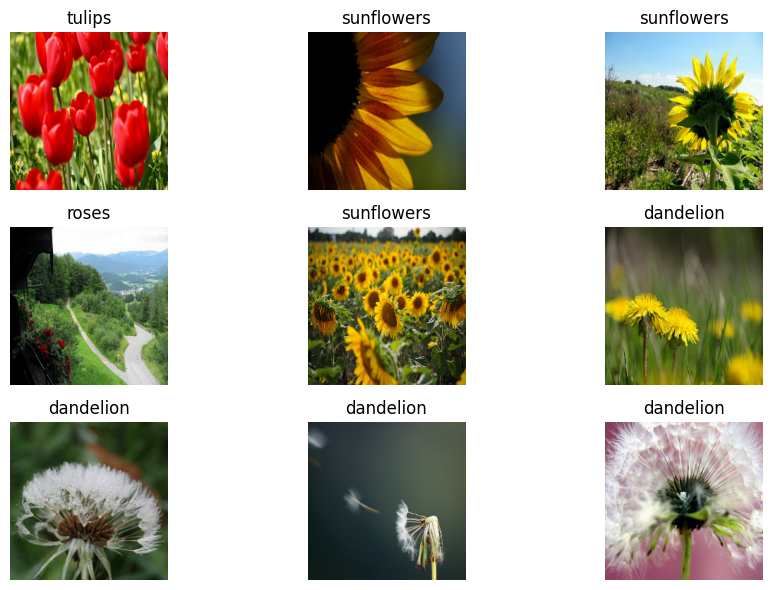

In [12]:
# Display 9 images from the raw dataset

import tensorflow as tf
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for images, labels in ds_train.map(
    lambda image, label: (
        tf.image.resize(image, (224, 224)),
        label
    )
).batch(9).take(1):

    for i in range(len(images)):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
base_model = VGG16(
weights="imagenet",
include_top=False,
input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)
print("VGG16 loaded.")
print("Base model output shape:", base_model.output_shape)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 64s 1us/step
VGG16 loaded.
Base model output shape: (None, 4, 4, 512)


In [14]:
base_model.trainable = False
print("Base model trainable:", base_model.trainable)

Base model trainable: False


In [15]:
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = models.Model(inputs, outputs)
model.compile(
optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
loss="categorical_crossentropy",
metrics=["accuracy"]
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,862,789 (56.70 MB)

 Trainable params: 148,101 (578.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
callbacks = [
EarlyStopping(
monitor="val_loss",
patience=4,
restore_best_weights=True
),
ReduceLROnPlateau(
monitor="val_loss",
factor=0.2,
patience=2,
min_lr=1e-6
)
]
history = model.fit(
train_ds,
validation_data=val_ds,
epochs=15,
callbacks=callbacks
)

Epoch 1/15


C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 ━━━━━━━━━━━━━━━━━━━━ 879s 11s/step - accuracy: 0.5621 - loss: 2.0264 - val_accuracy: 0.7459 - val_loss: 0.6923 - learning_rate: 0.0010
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.7470 - loss: 0.7387

In [ ]:
print("Training epochs completed:", len(history.history["loss"]))
print("Best validation accuracy:",
max(history.history["val_accuracy"]))
print("Best validation loss:", min(history.history["val_loss"]))
print("Final training accuracy:", history.history["accuracy"][-1])

In [ ]:
print("Epochs recorded:", len(history.history["loss"]))
print("Best epoch:",
history.history["val_loss"].index(
min(history.history["val_loss"])
) + 1)
print("Early stopping patience:",
callbacks[0].patience)

print("Restore best weights:",
callbacks[0].restore_best_weights)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation
accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
plt.tight_layout()
plt.show()